<a href="https://colab.research.google.com/github/SnehaGupta359/first-demo/blob/main/K_Nearest_Neighbor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [11]:
df = pd.read_csv("/content/diabetes.csv")

# Remove duplicate records
df = df.drop_duplicates()

print("Dataset Shape:", df.shape)

Dataset Shape: (744, 9)


In [12]:
# Replace invalid zero measurements with NaN
zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

for col in zero_columns:
    df[col] = df[col].replace(0, np.nan)

# Separate input and output
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (595, 8)
Testing data: (149, 8)


In [13]:
k_values = range(1, 22)

train_accuracy = []
test_accuracy = []
cv_accuracy = []

for k in k_values:

    model = Pipeline([

        ('imputer', SimpleImputer(strategy='median')),

        ('scaler', StandardScaler()),

        ('knn', KNeighborsClassifier(n_neighbors=k))

    ])

    # Train model
    model.fit(X_train, y_train)

    # Training accuracy
    train_pred = model.predict(X_train)

    train_accuracy.append(
        accuracy_score(y_train, train_pred) * 100
    )

    # Testing accuracy
    test_pred = model.predict(X_test)

    test_accuracy.append(
        accuracy_score(y_test, test_pred) * 100
    )

    # 5-fold cross-validation accuracy
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='accuracy'
    )

    cv_accuracy.append(scores.mean() * 100)


print("Accuracy calculation completed!")

Accuracy calculation completed!


In [14]:
results = pd.DataFrame({

    'K Value': list(k_values),

    'Training Accuracy': train_accuracy,

    'Testing Accuracy': test_accuracy,

    'CV Accuracy': cv_accuracy

})

print(results.round(2))

    K Value  Training Accuracy  Testing Accuracy  CV Accuracy
0         1             100.00             71.81        70.42
1         2              84.20             74.50        69.75
2         3              86.55             73.15        72.44
3         4              81.34             69.80        74.12
4         5              81.85             74.50        74.96
5         6              80.84             73.83        74.12
6         7              80.17             74.50        75.13
7         8              80.67             74.50        74.96
8         9              81.01             73.83        75.63
9        10              80.50             73.15        74.62
10       11              81.18             73.83        75.80
11       12              80.50             73.83        73.61
12       13              80.17             72.48        75.13
13       14              79.33             74.50        74.96
14       15              79.66             74.50        75.29
15      

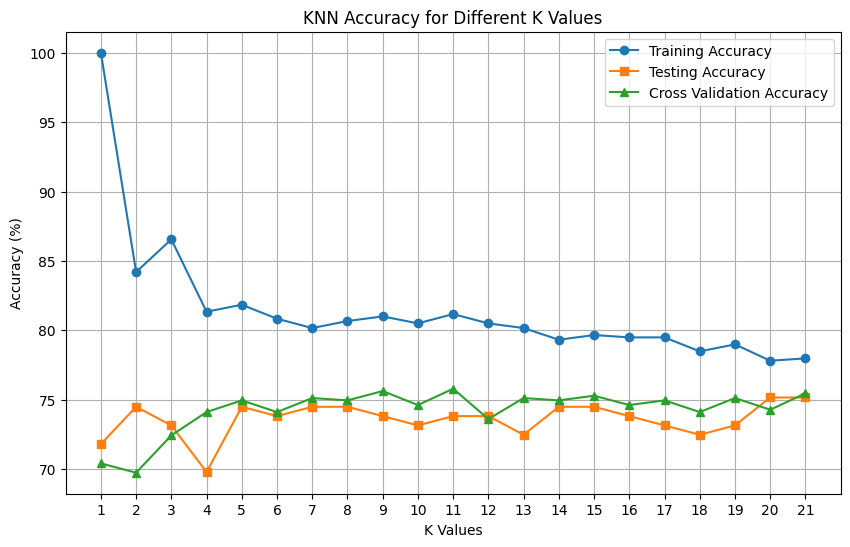

In [15]:
plt.figure(figsize=(10, 6))

plt.plot(
    k_values,
    train_accuracy,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    k_values,
    test_accuracy,
    marker='s',
    label='Testing Accuracy'
)

plt.plot(
    k_values,
    cv_accuracy,
    marker='^',
    label='Cross Validation Accuracy'
)

plt.xlabel("K Values")
plt.ylabel("Accuracy (%)")

plt.title("KNN Accuracy for Different K Values")

plt.xticks(list(k_values))

plt.legend()
plt.grid()

plt.show()

In [16]:
best_index = np.argmax(cv_accuracy)

best_k = list(k_values)[best_index]

print("Best K Value:", best_k)

print("Best CV Accuracy:",
      round(cv_accuracy[best_index], 2), "%")

Best K Value: 11
Best CV Accuracy: 75.8 %
